In [19]:
import numpy as np
import matplotlib.pyplot as plt

In [20]:
def gram_schmidt(B):
    """
    Compute the Gram--Schmidt vectors v_i^* and
    coefficients mu_{i,j}.
    """
    n = len(B)

    B_star = np.zeros_like(B, dtype=float)
    mu = np.zeros((n, n), dtype=float)

    for i in range(n):
        B_star[i] = B[i].astype(float)

        for j in range(i):
            mu[i, j] = (
                np.dot(B[i], B_star[j])
                / np.dot(B_star[j], B_star[j])
            )

            B_star[i] -= mu[i, j] * B_star[j]

    return B_star, mu

In [21]:
def lll(B, delta=3/4):
    """
    Implement the LLL algorithm.

    The basis vectors are given by the rows of B.
    """
    B = np.array(B, dtype=int).copy()
    n = len(B)

    # Step [2]
    k = 1       # Python indexing: k=1 corresponds to k=2 mathematically

    # Step [3]
    B_star, mu = gram_schmidt(B)

    swaps = 0
    k_values = []

    # Step [4]
    while k < n:

        # Record the mathematical value of k
        k_values.append(k + 1)

        # Steps [5]--[7]: Size reduction
        for j in range(k - 1, -1, -1):

            q = int(np.floor(mu[k, j] + 0.5))

            B[k] = B[k] - q * B[j]

            # Update Gram--Schmidt data
            B_star, mu = gram_schmidt(B)

        # Step [8]: Lovasz condition
        lhs = np.dot(B_star[k], B_star[k])

        rhs = ( delta - mu[k, k - 1]**2) * np.dot(B_star[k - 1], B_star[k - 1])

        # Step [9]
        if lhs >= rhs:
            k += 1

        # Steps [10]--[13]
        else:
            B[[k - 1, k]] = B[[k, k - 1]]

            B_star, mu = gram_schmidt(B)

            swaps += 1

            # max(k-1,2) in mathematical indexing
            k = max(k - 1, 1)

    # Step [14]
    return B, swaps, k_values

In [22]:
#calculate hadamard ratio
def hadamard_ratio(B):

    n = len(B) #dimension of L

    det = abs(np.linalg.det(B)) #determinant of L

    norms = np.linalg.norm(B,axis=1) #norms of each basis vector of L

    return (det / np.prod(norms))**(1/n)

#calculate shortest basis vector for a basis matrix
def shortest_basis_vector(B):
    lengths = [np.linalg.norm(v) for v in B]
    return min(lengths)


In [23]:
M = np.array([
    [19,  2, 32, 46,  3, 33],
    [15, 42, 11,  0,  3, 24],
    [43, 15,  0, 24,  4, 16],
    [20, 44, 44,  0, 18, 15],
    [ 0, 48, 35, 16, 31, 31],
    [48, 33, 32,  9,  1, 29]
])

M_LLL, swaps, k_values = lll(M)

print("LLL-reduced basis:")
print(M_LLL)

print("\nNumber of swap steps:", swaps)

print("\nSequence of k values:")
print(k_values)

# compare hadamard ratio before and after LLL
print("\nHadamard ratio of M:")
print(round(hadamard_ratio(M),5))

print("\nHadamard ratio of M after LLL:")
print(round(hadamard_ratio(M_LLL),5))

# compare the shortest basis vector before and after LLL
original_min = shortest_basis_vector(M)
reduced_min = shortest_basis_vector(M_LLL)

print("\nShortest vector before LLL:")
print(original_min)
print("\nShortest vector after LLL: ")
print(reduced_min)

LLL-reduced basis:
[[  7 -12  -8   4  19   9]
 [-20   4  -9  16  13  16]
 [  5   2  33   0  15  -9]
 [ -6  -7 -20 -21   8 -12]
 [-10 -24  21 -15  -6 -11]
 [  7   4  -9 -11   1  31]]

Number of swap steps: 19

Sequence of k values:
[2, 2, 3, 2, 3, 4, 3, 2, 2, 3, 4, 5, 4, 3, 2, 3, 4, 5, 4, 3, 4, 5, 6, 5, 4, 3, 4, 5, 6, 5, 4, 3, 2, 2, 3, 2, 3, 4, 5, 6]

Hadamard ratio of M:
0.46908

Hadamard ratio of M after LLL:
0.88824

Shortest vector before LLL:
51.91338940966964

Shortest vector after LLL: 
26.739483914241877


In [24]:
# Change the ordering of the basis vectors
M_reverse = M[::-1]

M_LLL_original, _, _ = lll(M, delta=3/4)
M_LLL_reverse, _, _ = lll(M_reverse, delta=3/4)

# Change the Lovasz parameter
M_LLL_099, _, _ = lll(M, delta=0.99)

print("LLL with original ordering:")
print(M_LLL_original)

print("\nLLL with reversed ordering:")
print(M_LLL_reverse)

print("\nLLL with delta = 0.99:")
print(M_LLL_099)



LLL with original ordering:
[[  7 -12  -8   4  19   9]
 [-20   4  -9  16  13  16]
 [  5   2  33   0  15  -9]
 [ -6  -7 -20 -21   8 -12]
 [-10 -24  21 -15  -6 -11]
 [  7   4  -9 -11   1  31]]

LLL with reversed ordering:
[[ -7  12   8  -4 -19  -9]
 [ 20  -4   9 -16 -13 -16]
 [-28  11  12  -9  17 -14]
 [ -6  -7 -20 -21   8 -12]
 [ -7  -4   9  11  -1 -31]
 [ 10  24 -21  15   6  11]]

LLL with delta = 0.99:
[[ -7  12   8  -4 -19  -9]
 [-20   4  -9  16  13  16]
 [  6   7  20  21  -8  12]
 [-28  11  12  -9  17 -14]
 [ -7  -4   9  11  -1 -31]
 [-10 -24  21 -15  -6 -11]]


In [25]:
# ============================================================
# Comparison tests
# ============================================================

# ------------------------------------------------------------
# 1. Original ordering vs reversed ordering
# ------------------------------------------------------------

M_reverse = M[::-1]

M_LLL_original, swaps_original, k_original = lll(M, delta=3/4)
M_LLL_reverse, swaps_reverse, k_reverse = lll(M_reverse, delta=3/4)

print("=" * 60)
print("1. Effect of changing the ordering")
print("=" * 60)

print("\nOriginal ordering:")
print("Number of swaps:", swaps_original)
print("Hadamard ratio:", round(hadamard_ratio(M_LLL_original), 5))
print("Shortest basis vector:",
      round(shortest_basis_vector(M_LLL_original), 5))

print("\nReversed ordering:")
print("Number of swaps:", swaps_reverse)
print("Hadamard ratio:", round(hadamard_ratio(M_LLL_reverse), 5))
print("Shortest basis vector:",
      round(shortest_basis_vector(M_LLL_reverse), 5))


# ------------------------------------------------------------
# 2. Compare the k-sequences
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("2. Sequence of k values")
print("=" * 60)

print("\nOriginal ordering:")
print(k_original)

print("\nReversed ordering:")
print(k_reverse)


# ------------------------------------------------------------
# 3. Effect of changing delta
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("3. Effect of changing the Lovasz parameter delta")
print("=" * 60)

deltas = [0.75, 0.85, 0.90, 0.95, 0.99]

print(f"{'delta':<10}{'swaps':<10}{'H(B)':<15}{'shortest vector':<20}")
print("-" * 55)

for delta in deltas:

    B_LLL, swaps, k_values = lll(M, delta=delta)

    H = hadamard_ratio(B_LLL)
    shortest = shortest_basis_vector(B_LLL)

    print(f"{delta:<10.2f}"
          f"{swaps:<10}"
          f"{H:<15.5f}"
          f"{shortest:<20.5f}")


# ------------------------------------------------------------
# 4. Compare determinant before and after reduction
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("4. Determinant preservation")
print("=" * 60)

det_original = abs(round(np.linalg.det(M)))
det_reduced = abs(round(np.linalg.det(M_LLL_original)))

print("Original determinant:", det_original)
print("Reduced determinant :", det_reduced)
print("Determinant preserved:", det_original == det_reduced)


# ------------------------------------------------------------
# 5. Overall comparison
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("5. Overall comparison")
print("=" * 60)

print(f"{'Case':<25}"
      f"{'delta':<10}"
      f"{'swaps':<10}"
      f"{'H(B)':<12}"
      f"{'shortest':<15}")

print("-" * 72)

# Original ordering
print(f"{'Original ordering':<25}"
      f"{'0.75':<10}"
      f"{swaps_original:<10}"
      f"{hadamard_ratio(M_LLL_original):<12.5f}"
      f"{shortest_basis_vector(M_LLL_original):<15.5f}")

# Reversed ordering
print(f"{'Reversed ordering':<25}"
      f"{'0.75':<10}"
      f"{swaps_reverse:<10}"
      f"{hadamard_ratio(M_LLL_reverse):<12.5f}"
      f"{shortest_basis_vector(M_LLL_reverse):<15.5f}")

# Delta = 0.99
M_LLL_099, swaps_099, k_099 = lll(M, delta=0.99)

print(f"{'Original ordering':<25}"
      f"{'0.99':<10}"
      f"{swaps_099:<10}"
      f"{hadamard_ratio(M_LLL_099):<12.5f}"
      f"{shortest_basis_vector(M_LLL_099):<15.5f}")

1. Effect of changing the ordering

Original ordering:
Number of swaps: 19
Hadamard ratio: 0.88824
Shortest basis vector: 26.73948

Reversed ordering:
Number of swaps: 11
Hadamard ratio: 0.87897
Shortest basis vector: 26.73948

2. Sequence of k values

Original ordering:
[2, 2, 3, 2, 3, 4, 3, 2, 2, 3, 4, 5, 4, 3, 2, 3, 4, 5, 4, 3, 4, 5, 6, 5, 4, 3, 4, 5, 6, 5, 4, 3, 2, 2, 3, 2, 3, 4, 5, 6]

Reversed ordering:
[2, 2, 3, 2, 2, 3, 4, 3, 4, 5, 4, 3, 4, 5, 6, 5, 4, 3, 2, 2, 3, 4, 5, 6]

3. Effect of changing the Lovasz parameter delta
delta     swaps     H(B)           shortest vector     
-------------------------------------------------------
0.75      19        0.88824        26.73948            
0.85      21        0.87897        26.73948            
0.90      22        0.87897        26.73948            
0.95      22        0.87897        26.73948            
0.99      22        0.87897        26.73948            

4. Determinant preservation
Original determinant: 777406251
Reduced det

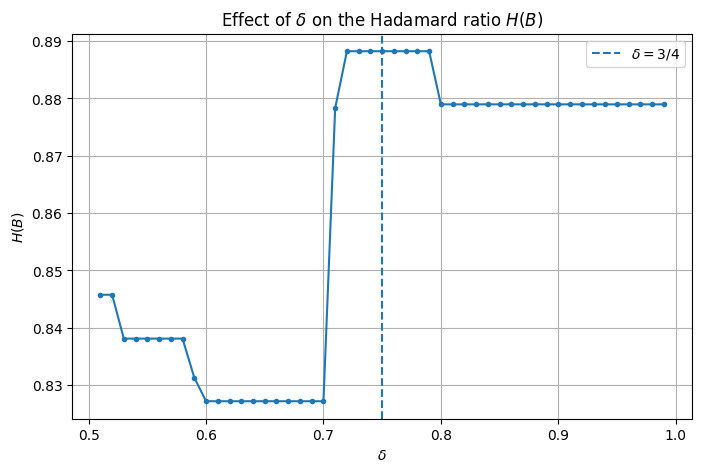

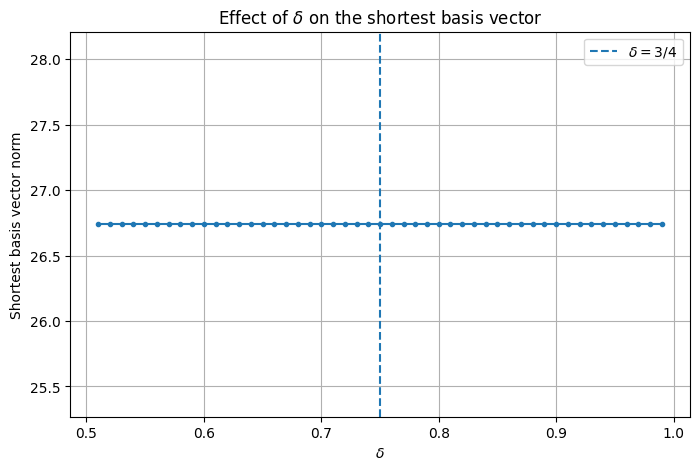

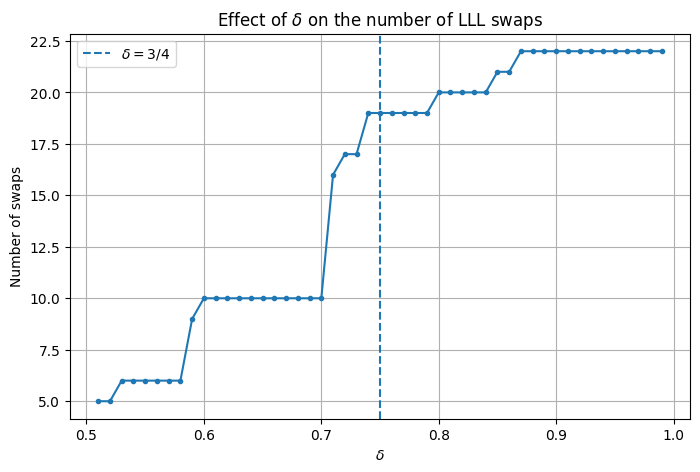

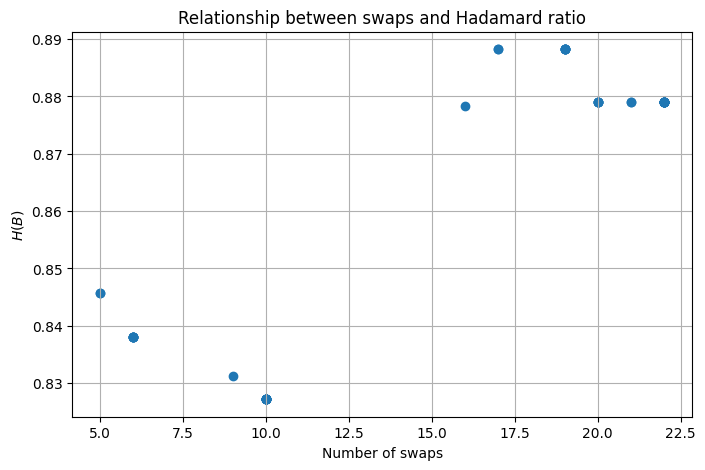

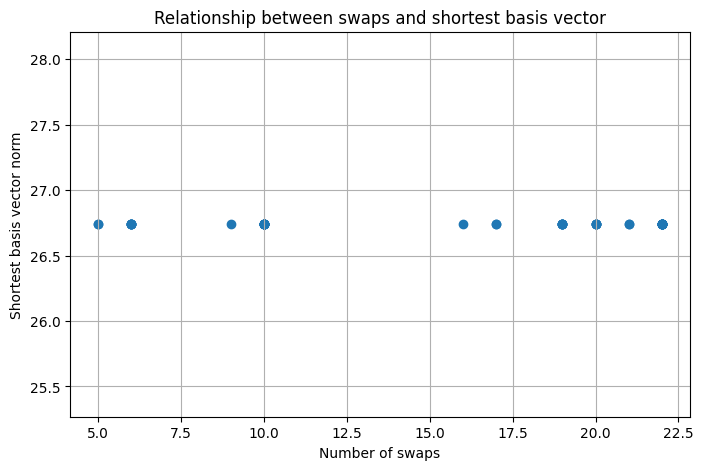

In [26]:
# ============================================================
# Investigating the effect of delta
# ============================================================

# Use a range of delta values
deltas = np.linspace(0.51, 0.99, 49)

hadamard_values = []
shortest_values = []
swap_values = []

for delta in deltas:

    B_LLL, swaps, k_values = lll(M, delta=delta)

    hadamard_values.append(hadamard_ratio(B_LLL))
    shortest_values.append(shortest_basis_vector(B_LLL))
    swap_values.append(swaps)


# ------------------------------------------------------------
# 1. Delta vs Hadamard ratio
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(deltas, hadamard_values, marker='o', markersize=3)

plt.axvline(3/4, linestyle='--',
            label=r'$\delta=3/4$')

plt.xlabel(r'$\delta$')
plt.ylabel(r'$H(B)$')
plt.title(r'Effect of $\delta$ on the Hadamard ratio $H(B)$')
plt.legend()
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 2. Delta vs shortest basis vector
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(deltas, shortest_values, marker='o', markersize=3)

plt.axvline(3/4, linestyle='--',
            label=r'$\delta=3/4$')

plt.xlabel(r'$\delta$')
plt.ylabel('Shortest basis vector norm')
plt.title(r'Effect of $\delta$ on the shortest basis vector')
plt.legend()
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 3. Delta vs number of swaps
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(deltas, swap_values, marker='o', markersize=3)

plt.axvline(3/4, linestyle='--',
            label=r'$\delta=3/4$')

plt.xlabel(r'$\delta$')
plt.ylabel('Number of swaps')
plt.title(r'Effect of $\delta$ on the number of LLL swaps')
plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Investigating the relationship between swaps and basis quality
# ============================================================

# ------------------------------------------------------------
# 4. Number of swaps vs Hadamard ratio
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(swap_values, hadamard_values)

plt.xlabel('Number of swaps')
plt.ylabel(r'$H(B)$')
plt.title(r'Relationship between swaps and Hadamard ratio')
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 5. Number of swaps vs shortest basis vector
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(swap_values, shortest_values)

plt.xlabel('Number of swaps')
plt.ylabel('Shortest basis vector norm')
plt.title(r'Relationship between swaps and shortest basis vector')
plt.grid(True)

plt.show()